# AI Safety Standards for Automated Driving: ISO/PAS 8800 and Related Standards

**Module 06 · AI Safety (ISO/PAS 8800)** · Notebook 1 of 7

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/milinpatel07/Autonomous-Driving_AI-Safety-and-Security/blob/main/06_AI_Safety_ISO_PAS_8800/01_ai_safety_standards.ipynb)

| Level | Time | Prerequisites | Standards |
|---|---|---|---|
| Intermediate | ~75 min | [ISO 26262 fundamentals](../03_Functional_Safety_ISO26262/01_iso26262_fundamentals.ipynb), [SOTIF fundamentals](../04_SOTIF_ISO21448/01_sotif_fundamentals.ipynb) | ISO/PAS 8800:2024, ISO/IEC TR 5469:2024, ISO/TS 5083:2025, UL 4600 (3rd ed., 2023) |

**Author:** Milin Patel · Hochschule Kempten · MIT Licence

## Learning objectives

After this notebook you should be able to:

- Explain why machine-learning (ML) components need safety guidance beyond ISO 26262 and ISO 21448.
- Describe the scope and structure of **ISO/PAS 8800:2024** *Road vehicles — Safety and artificial intelligence*: AI safety lifecycle, AI system / AI component / AI model, AI safety requirements, data-related considerations, verification and validation, safety analysis, assurance argument, and measures during operation.
- Draw a sharp boundary between ISO 26262 (E/E malfunctions), ISO 21448 (functional insufficiencies and triggering conditions) and ISO/PAS 8800 (AI-specific insufficiencies and errors).
- Place the surrounding documents correctly: ISO/IEC TR 5469, ISO/IEC 22989, ISO/IEC 42001, ISO/IEC 5259, ISO/TS 5083, UL 4600 and the EU AI Act.
- Turn data-quality wishes into **verifiable dataset requirements** derived from the ODD and the AI safety requirements.
- Explain why field monitoring of an ML component relies on label-free proxies plus periodic labelled audits.

In [1]:
# Setup: standard scientific Python stack only (all pre-installed on Colab)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Circle, Patch
from IPython.display import display
from sklearn.metrics import cohen_kappa_score
from sklearn.model_selection import GroupShuffleSplit, ShuffleSplit

rng = np.random.default_rng(42)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
# Okabe-Ito colour-blind-safe palette
OI = ["#E69F00", "#56B4E9", "#009E73", "#F0E442", "#0072B2", "#D55E00", "#CC79A7", "#000000"]
print("Setup complete.")

Setup complete.


## 1. Why AI needs specific safety guidance

**Conventionally specified software**
- Behaviour is written down as explicit requirements and design.
- Failures are traced to specification, design or implementation faults.
- Verification against the specification is possible with structural and requirements-based coverage criteria.

**ML components**
- Behaviour is *learned from data*; the "specification" is partly implicit in the training set.
- Inference is usually deterministic, but performance is a *statistical* property over an input distribution.
- Errors are often not traceable to a single faulty line of code, and the input space (images, point clouds) cannot be enumerated.
- Coverage criteria from ISO 26262-6 (e.g. statement/branch coverage) say little about whether a neural network generalises.

### Key AI safety challenges

1. **Opacity**: learned representations are hard to inspect (see [06 Explainability](06_explainability.ipynb)).
2. **Data dependency**: performance depends on how well training and test data represent the operational design domain (ODD).
3. **Distribution shift**: performance can degrade on inputs that differ from the training distribution (see [02_Failures_and_Robustness/03 OOD detection](../02_Failures_and_Robustness/03_out_of_distribution_detection.ipynb)).
4. **Adversarial vulnerability**: small, crafted input changes can flip predictions (see [02_Failures_and_Robustness/04 Adversarial attacks](../02_Failures_and_Robustness/04_adversarial_attacks.ipynb)).
5. **Uncertainty**: a softmax score is not automatically a calibrated probability (see [02](02_uncertainty_types.ipynb)–[05](05_conformal_prediction.ipynb)).
6. **Change over time**: retraining and over-the-air updates can introduce new insufficiencies, so the safety argument must be maintained during operation.

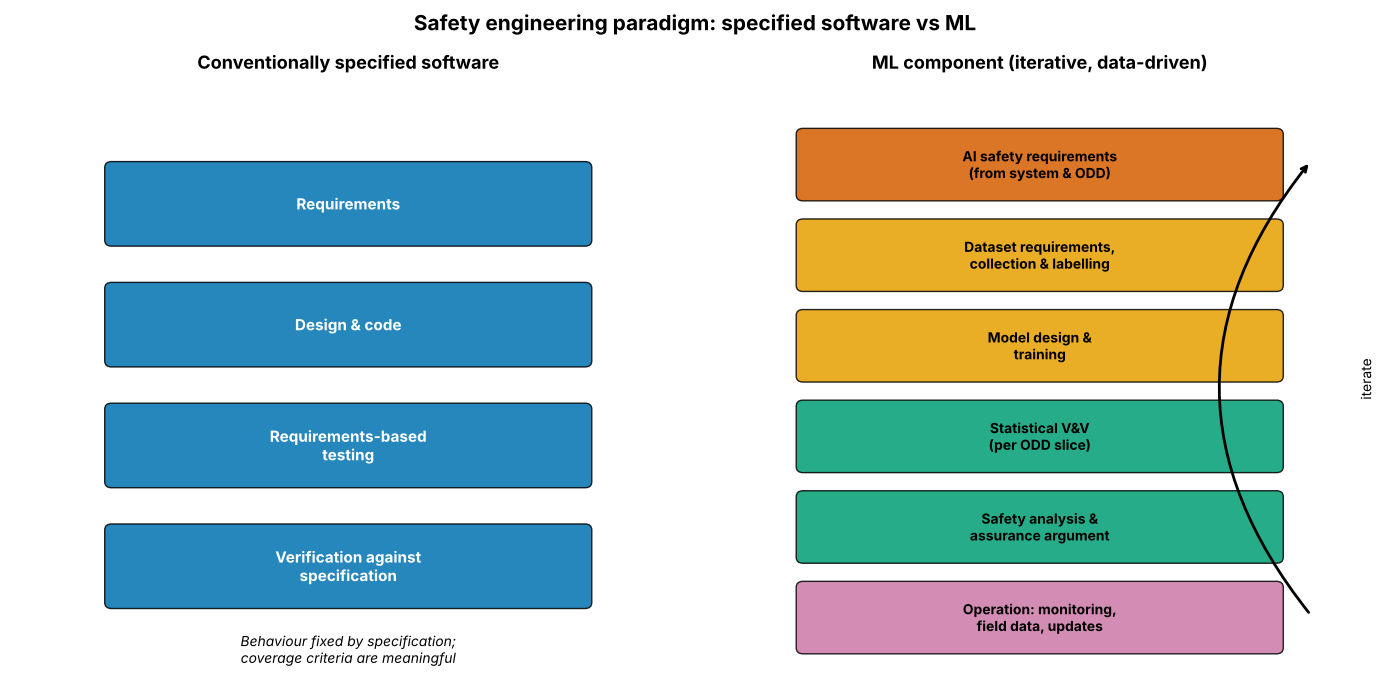

In [2]:
def visualize_safety_paradigm():
    """Contrast a conventional V-model view with the iterative, data-driven ML lifecycle."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7))
    trad = [(0.8, "Requirements"), (0.6, "Design & code"),
            (0.4, "Requirements-based\ntesting"), (0.2, "Verification against\nspecification")]
    for y, text in trad:
        ax1.add_patch(FancyBboxPatch((0.15, y - 0.07), 0.7, 0.12, boxstyle="round,pad=0.01",
                                     facecolor=OI[4], edgecolor="black", alpha=0.85))
        ax1.text(0.5, y - 0.01, text, ha="center", va="center", fontsize=11, color="white", fontweight="bold")
    ax1.set_title("Conventionally specified software", fontsize=13, fontweight="bold")
    ax1.text(0.5, 0.03, "Behaviour fixed by specification;\ncoverage criteria are meaningful",
             ha="center", fontsize=10, style="italic")
    ai = [(0.86, "AI safety requirements\n(from system & ODD)"), (0.71, "Dataset requirements,\ncollection & labelling"),
          (0.56, "Model design &\ntraining"), (0.41, "Statistical V&V\n(per ODD slice)"),
          (0.26, "Safety analysis &\nassurance argument"), (0.11, "Operation: monitoring,\nfield data, updates")]
    for i, (y, text) in enumerate(ai):
        ax2.add_patch(FancyBboxPatch((0.15, y - 0.055), 0.7, 0.10, boxstyle="round,pad=0.01",
                                     facecolor=[OI[5], OI[0], OI[0], OI[2], OI[2], OI[6]][i],
                                     edgecolor="black", alpha=0.85))
        ax2.text(0.5, y - 0.005, text, ha="center", va="center", fontsize=10, color="black", fontweight="bold")
    ax2.annotate("", xy=(0.9, 0.86), xytext=(0.9, 0.11),
                 arrowprops=dict(arrowstyle="->", lw=2, connectionstyle="arc3,rad=-0.4"))
    ax2.text(0.97, 0.5, "iterate", rotation=90, va="center", fontsize=10)
    ax2.set_title("ML component (iterative, data-driven)", fontsize=13, fontweight="bold")
    for ax in (ax1, ax2):
        ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis("off")
    fig.suptitle("Safety engineering paradigm: specified software vs ML", fontsize=15, fontweight="bold")
    plt.tight_layout(); plt.show()

visualize_safety_paradigm()

## 2. The standards landscape (as of October 2026)

The table distinguishes **normative** documents (requirements you can claim conformance to), **specifications** that are not yet full International Standards (PAS, TS), and **informative** reports (TR) that give guidance but impose no requirements.

| Document | Type | What it covers | Role for AV perception |
|---|---|---|---|
| ISO 26262:2018 (12 parts) | International Standard | Functional safety of E/E systems: malfunctions from systematic and random hardware faults | Baseline process; the HW/SW running the ML component |
| ISO 21448:2022 (SOTIF) | International Standard | Hazards from functional insufficiencies (specification or performance) and triggering conditions, without a fault | Perception performance limits, scenario Areas 1–4 |
| **ISO/PAS 8800:2024** | Publicly Available Specification (ISO/TC 22/SC 32), Ed. 1, Dec 2024 | Safety of AI systems in road vehicles; tailors and extends ISO 26262 and ISO 21448 for AI | Main reference for ML-based perception safety |
| ISO/IEC TR 5469:2024 | Technical Report (informative, JTC 1/SC 42) | Functional safety and AI systems, cross-domain | Background: properties, risk factors, V&V techniques |
| ISO/IEC TS 22440 (under development) | Technical Specification (draft) | Functional safety and AI systems — requirements | Cross-domain successor work to TR 5469 |
| ISO/IEC 22989:2022 | International Standard | AI concepts and terminology (incl. trustworthiness characteristics) | Shared vocabulary |
| ISO/IEC TR 24028:2020 | Technical Report | Overview of trustworthiness in AI | Survey of threats, vulnerabilities and mitigations |
| ISO/IEC 23894:2023 | International Standard (guidance) | AI risk management (builds on ISO 31000) | Organisational risk process |
| ISO/IEC 42001:2023 | Management-system standard | AI management system (certifiable at organisation level) | Organisational governance, not product safety |
| ISO/IEC 5259-1 to -5 (2024–2025) | International Standards | Data quality for analytics and ML: terminology, measures, management, process, governance | Measures for dataset requirements |
| ISO/TS 5083:2025 | Technical Specification, Apr 2025 | Safety for automated driving systems (L3/L4): design, V&V, post-deployment | ADS-level safety case above the component level |
| UL 4600 (3rd ed., 2023) | ANSI/UL standard | Safety case for autonomous products; safety performance indicators (SPIs) | Assessable safety case incl. ML |
| NIST AI RMF 1.0 (2023) | Voluntary framework (US) | AI risk management functions: govern, map, measure, manage | Organisational practice |
| EU AI Act, Reg. (EU) 2024/1689 | EU law | Horizontal AI regulation; vehicles covered indirectly (Section 6) | Regulatory context |

Sources: ISO catalogue entries for [ISO/PAS 8800](https://www.iso.org/standard/83303.html), [ISO/TS 5083](https://www.iso.org/standard/81920.html), [ISO/IEC 5259-1](https://www.iso.org/standard/81088.html); [UL 4600](https://www.ul.com/news/ul-4600-edition-3-updates-incorporate-autonomous-trucking); [NIST AI RMF](https://www.nist.gov/itl/ai-risk-management-framework). ISO/IEC TS 22440 status: [ISO project page](https://www.iso.org/standard/89535.html) (draft stage as of October 2026). A 3rd edition of ISO 26262 is in development; publication reported for around 2028, date not final, and its content is not final either (as of October 2026, [Omnex, Jul 2026](https://blog.omnex.com/2026/07/02/automotive-standards-update-spice-pam-4-0-iso-26262-ed-3-functional-safety-iso-21434-2/)).

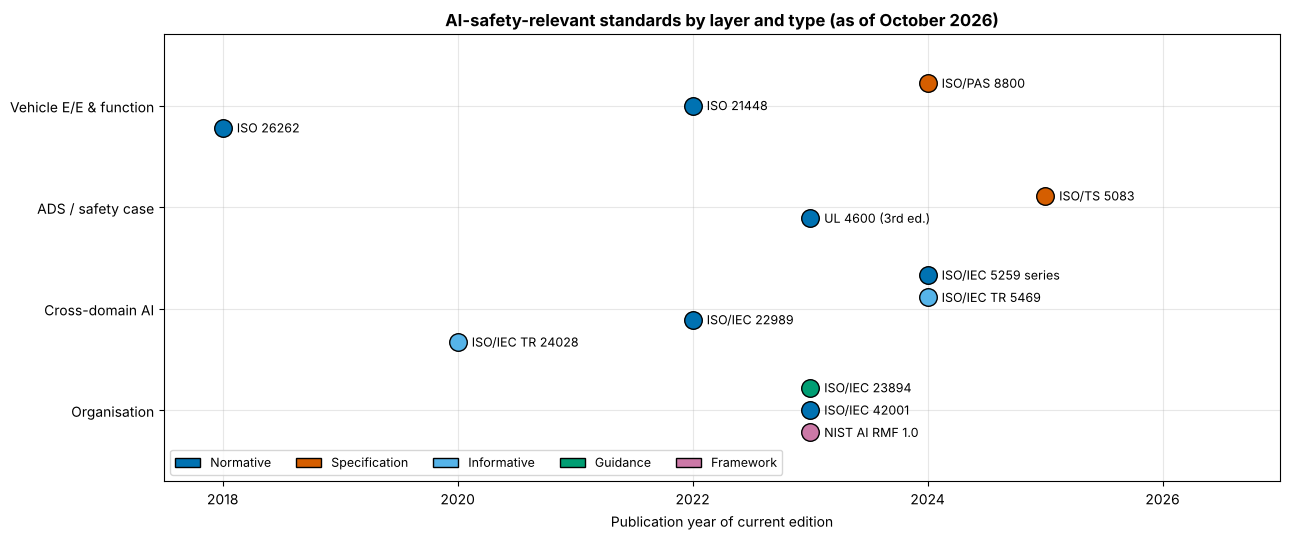

Organisation            : NIST AI RMF 1.0 (2023, Framework); ISO/IEC 42001 (2023, Normative); ISO/IEC 23894 (2023, Guidance)
Cross-domain AI         : ISO/IEC TR 24028 (2020, Informative); ISO/IEC 22989 (2022, Normative); ISO/IEC TR 5469 (2024, Informative); ISO/IEC 5259 series (2024, Normative)
ADS / safety case       : UL 4600 (3rd ed.) (2023, Normative); ISO/TS 5083 (2025, Specification)
Vehicle E/E & function  : ISO 26262 (2018, Normative); ISO 21448 (2022, Normative); ISO/PAS 8800 (2024, Specification)


In [3]:
# The same landscape as data, so that the figure is derived from the table above
standards = pd.DataFrame([
    # name,                    year, layer,                     nature
    ("NIST AI RMF 1.0",         2023, "Organisation",          "Framework"),
    ("ISO/IEC 42001",           2023, "Organisation",          "Normative"),
    ("ISO/IEC 23894",           2023, "Organisation",          "Guidance"),
    ("ISO/IEC 22989",           2022, "Cross-domain AI",       "Normative"),
    ("ISO/IEC TR 24028",        2020, "Cross-domain AI",       "Informative"),
    ("ISO/IEC TR 5469",         2024, "Cross-domain AI",       "Informative"),
    ("ISO/IEC 5259 series",     2024, "Cross-domain AI",       "Normative"),
    ("UL 4600 (3rd ed.)",       2023, "ADS / safety case",     "Normative"),
    ("ISO/TS 5083",             2025, "ADS / safety case",     "Specification"),
    ("ISO 26262",               2018, "Vehicle E/E & function", "Normative"),
    ("ISO 21448",               2022, "Vehicle E/E & function", "Normative"),
    ("ISO/PAS 8800",            2024, "Vehicle E/E & function", "Specification"),
], columns=["document", "year", "layer", "nature"])

layers = ["Organisation", "Cross-domain AI", "ADS / safety case", "Vehicle E/E & function"]
nat_colour = {"Normative": OI[4], "Specification": OI[5], "Informative": OI[1],
              "Guidance": OI[2], "Framework": OI[6]}

fig, ax = plt.subplots(figsize=(13, 5.5))
for li, layer in enumerate(layers):
    sub = standards[standards.layer == layer].sort_values("year")
    for k, (_, r) in enumerate(sub.iterrows()):
        y = li + (k - (len(sub) - 1) / 2) * 0.22
        ax.scatter(r.year, y, s=160, color=nat_colour[r.nature], edgecolor="black", zorder=3)
        ax.text(r.year + 0.12, y, r.document, va="center", fontsize=9)
ax.set_yticks(range(len(layers))); ax.set_yticklabels(layers)
ax.set_xlim(2017.5, 2027); ax.set_ylim(-0.7, len(layers) - 0.3)
ax.set_xlabel("Publication year of current edition")
ax.set_title("AI-safety-relevant standards by layer and type (as of October 2026)", fontweight="bold")
ax.legend(handles=[Patch(facecolor=c, edgecolor="black", label=n) for n, c in nat_colour.items()],
          loc="lower left", fontsize=9, ncol=5)
plt.tight_layout(); plt.show()

# Text summary (screen-reader friendly), derived from the table
for layer in layers:
    sub = standards[standards.layer == layer].sort_values("year")
    print(f"{layer:24s}: " + "; ".join(f"{d} ({y}, {n})" for d, y, n in sub[["document", "year", "nature"]].values))

## 3. ISO/PAS 8800:2024 in detail

### 3.1 Scope and status
- **Title:** ISO/PAS 8800:2024 *Road vehicles — Safety and artificial intelligence*; Edition 1, published December 2024, 172 pages ([ISO](https://www.iso.org/standard/83303.html)).
- It is a **PAS** (Publicly Available Specification), i.e. a consensus document with a shorter route than an International Standard; it is expected to be revised in the light of experience.
- It applies to **safety-related E/E systems in series-production road vehicles that contain AI** (mopeds excluded), and is designed to be used **together with ISO 26262 and ISO 21448**. Non-AI elements remain under ISO 26262.
- It is technology-agnostic in principle, but most of its guidance targets machine learning, in particular supervised deep learning used for perception.

### 3.2 Key concepts (paraphrased; see the terms and definitions clause of the PAS for exact wording)
- 8800 reuses the ISO 26262 hierarchy of *system*, *element* and *component*.
- **AI system**: a system that contains one or more AI elements alongside conventional elements.
- **AI element / AI component**: an element of that system that implements AI technology, typically an **AI model** (the trained network) together with conventional pre- and post-processing.
- Safety requirements are allocated down this hierarchy; requirements on the AI model itself are expressed through measurable properties.
- **AI error / functional insufficiency**: an incorrect output of the AI component that can contribute to hazardous behaviour. 8800 relates AI errors to the cause–effect chain of ISO 21448 (triggering condition → functional insufficiency → output insufficiency → hazardous behaviour) and to the fault–error–failure chain of ISO 26262.
- **Safety-related properties** of the AI system, for example accuracy in each ODD slice, robustness, generalisation, quality of uncertainty estimates and timing, are used to express AI safety requirements in verifiable form.

### 3.3 Structure (main topics)

The clause numbers below follow published summaries of the PAS (e.g. [LHP](https://www.lhpes.com/blog/what-is-iso-pas-8800), [PwC Japan](https://www.pwc.com/jp/ja/knowledge/column/safety-and-artificial-intelligence.html)); check them against your copy of the document.

| Clause (per summaries) | Topic | What it asks for, in short |
|---|---|---|
| 7 | AI safety management | Tailored safety management and an **iterative reference AI safety lifecycle** |
| 8 | Assurance argument for AI systems | Structured argument that the AI safety requirements are met, with evidence from lifecycle work products and an evaluation of residual risk |
| 9 | Derivation of AI safety requirements | Refine system safety requirements into requirements on the AI system, expressed via safety-related properties and the ODD |
| 10 | Selection of AI technologies, architectural and development measures | Architecture (e.g. redundancy, monitors, safety envelopes) and development measures that address AI errors |
| 11 | Data-related considerations | A **dataset lifecycle**: dataset requirements → design → implementation (collection, labelling) → verification → validation → maintenance |
| 12 | Verification and validation of the AI system | Testing per ODD slice, robustness and generalisation checks, independence of test data |
| 13 | Safety analysis of AI systems | Systematic identification of AI errors, their root causes and their effects |
| 14 | Measures during operation | Field monitoring, data collection, incident handling and controlled updates so that the argument stays valid |
| 15 | Confidence in AI frameworks and software tools | Tool confidence for training frameworks and toolchains, in the spirit of ISO 26262-8 |

Informative annexes include a gap analysis of ISO 26262 for ML and worked examples.

### 3.4 The AI safety lifecycle in one picture
The lifecycle is iterative: each iteration identifies functional insufficiencies and their causes, improves the data, model or architecture, and repeats verification until the AI safety requirements are demonstrated and the assurance argument is judged adequate. After release, operation feeds field data back into the loop.

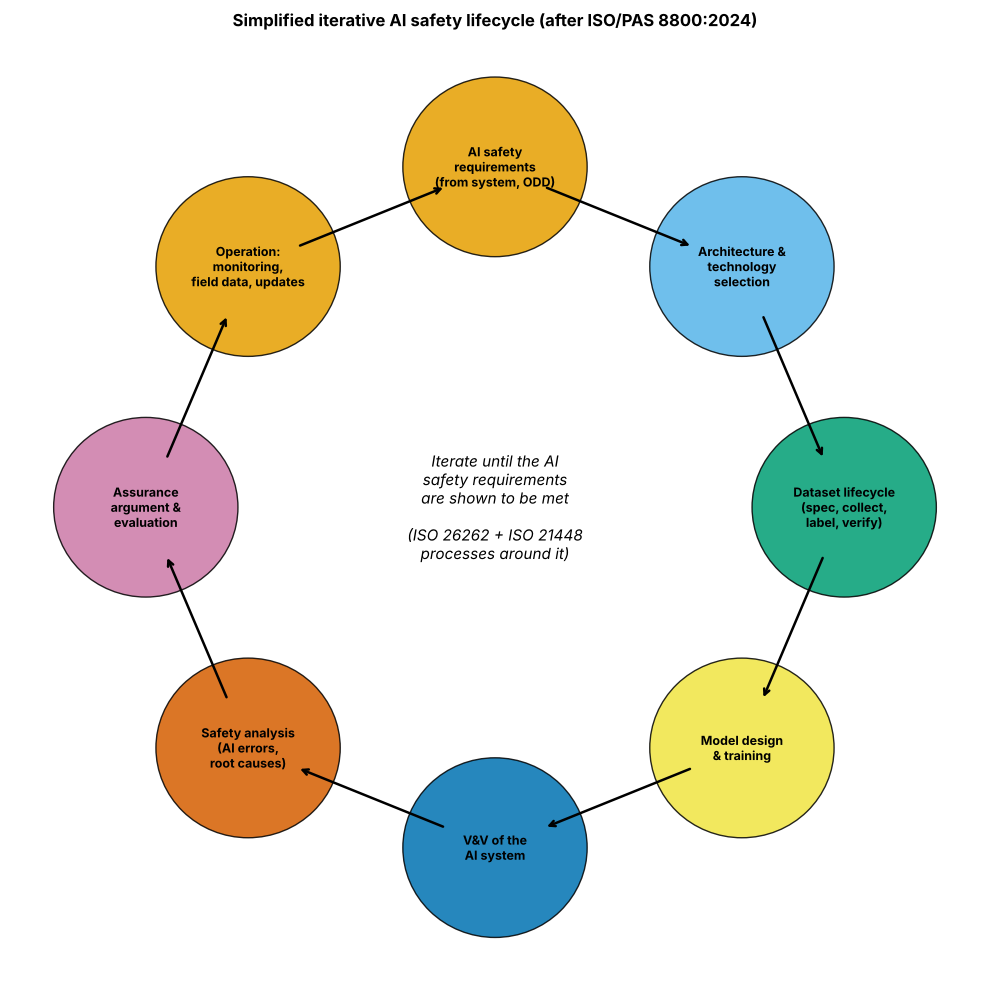

In [4]:
def draw_lifecycle():
    steps = ["AI safety\nrequirements\n(from system, ODD)", "Architecture &\ntechnology\nselection",
             "Dataset lifecycle\n(spec, collect,\nlabel, verify)", "Model design\n& training",
             "V&V of the\nAI system", "Safety analysis\n(AI errors,\nroot causes)",
             "Assurance\nargument &\nevaluation", "Operation:\nmonitoring,\nfield data, updates"]
    fig, ax = plt.subplots(figsize=(10, 10))
    n = len(steps); R = 0.36
    pts = []
    for i, s in enumerate(steps):
        a = np.pi / 2 - 2 * np.pi * i / n
        x, y = 0.5 + R * np.cos(a), 0.5 + R * np.sin(a)
        pts.append((x, y))
        ax.add_patch(Circle((x, y), 0.095, facecolor=OI[i % 7], edgecolor="black", alpha=0.85))
        ax.text(x, y, s, ha="center", va="center", fontsize=9, fontweight="bold")
    for i in range(n):
        (x0, y0), (x1, y1) = pts[i], pts[(i + 1) % n]
        ax.annotate("", xy=(x0 + 0.8 * (x1 - x0), y0 + 0.8 * (y1 - y0)),
                    xytext=(x0 + 0.2 * (x1 - x0), y0 + 0.2 * (y1 - y0)),
                    arrowprops=dict(arrowstyle="->", lw=1.8))
    ax.text(0.5, 0.5, "Iterate until the AI\nsafety requirements\nare shown to be met\n\n(ISO 26262 + ISO 21448\nprocesses around it)",
            ha="center", va="center", fontsize=11, style="italic")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis("off")
    ax.set_title("Simplified iterative AI safety lifecycle (after ISO/PAS 8800:2024)", fontweight="bold")
    plt.tight_layout(); plt.show()

draw_lifecycle()

### 3.5 Where the three automotive standards meet

| Cause of hazardous behaviour | Primary standard | Example in a camera-based pedestrian detector |
|---|---|---|
| E/E malfunction (random HW fault, systematic SW/HW fault) | ISO 26262 | Bit flip in accelerator memory, software bug in non-maximum suppression |
| Functional insufficiency triggered by a condition, no fault | ISO 21448 | Missed pedestrian in low sun glare (triggering condition) |
| AI-specific insufficiency or error (data, model, training) | ISO/PAS 8800, tailoring both of the above | Under-represented night-time children in the training set; poor generalisation; overconfident scores |

ISO/PAS 8800 is therefore **not an independent third layer**: it refines the ISO 26262 and ISO 21448 activities for AI elements. ISO/TS 5083 and UL 4600 sit above all three at the level of the automated driving system and its safety case.

## 4. Trustworthiness characteristics

ISO/IEC 22989:2022 defines the AI vocabulary, and ISO/IEC TR 24028:2020 surveys trustworthiness of AI. A teaching selection of characteristics relevant to automotive safety:

| Characteristic | Working definition | Typical evidence for perception |
|---|---|---|
| Robustness | Ability to maintain the required performance under perturbations and shifts within the ODD | Corruption benchmarks, per-condition test slices |
| Explainability / interpretability | Ability to express important factors behind an output in human-understandable form | Saliency checks, concept tests (see [06](06_explainability.ipynb)) |
| Transparency | Openness about data, design, capabilities and limitations | Dataset and model documentation |
| Fairness / representativeness | Absence of unjustified performance differences across groups | Recall per pedestrian age group, skin tone, mobility aid |
| Reliability | Ability to perform as required over time and conditions | Long-run field statistics |
| Safety | Freedom from unreasonable risk (ISO 26262-1:2018, 3.132) | The assurance argument as a whole |

> **Illustrative data:** values below are synthetic, chosen for teaching; they are not measurements.

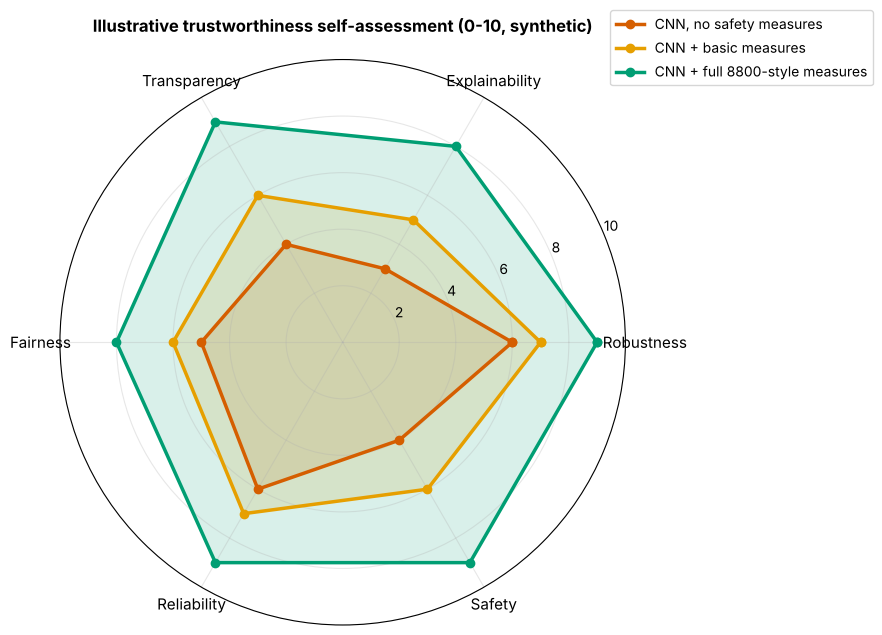

,Robustness,Explainability,Transparency,Fairness,Reliability,Safety,Mean
"CNN, no safety measures",6,3,4,5,6,4,4.7
CNN + basic measures,7,5,6,6,7,6,6.2
CNN + full 8800-style measures,9,8,9,8,9,9,8.7


Note: such radar scores are a communication aid only; no standard defines them. Evidence must come from requirement-specific verification (Section 5).


In [5]:
characteristics = ["Robustness", "Explainability", "Transparency", "Fairness", "Reliability", "Safety"]
# Illustrative values, not measured
systems = {
    "CNN, no safety measures": [6, 3, 4, 5, 6, 4],
    "CNN + basic measures": [7, 5, 6, 6, 7, 6],
    "CNN + full 8800-style measures": [9, 8, 9, 8, 9, 9],
}
angles = np.linspace(0, 2 * np.pi, len(characteristics), endpoint=False).tolist()
angles += angles[:1]
fig, ax = plt.subplots(figsize=(8, 7), subplot_kw=dict(projection="polar"))
for (name, scores), c in zip(systems.items(), [OI[5], OI[0], OI[2]]):
    vals = scores + scores[:1]
    ax.plot(angles, vals, "o-", lw=2.5, label=name, color=c)
    ax.fill(angles, vals, alpha=0.15, color=c)
ax.set_xticks(angles[:-1]); ax.set_xticklabels(characteristics, fontsize=11)
ax.set_ylim(0, 10)
ax.set_title("Illustrative trustworthiness self-assessment (0-10, synthetic)", fontweight="bold", pad=20)
ax.legend(loc="upper right", bbox_to_anchor=(1.45, 1.1))
plt.tight_layout(); plt.show()

df = pd.DataFrame(systems, index=characteristics).T
df["Mean"] = df.mean(axis=1).round(1)
display(df)
print("Note: such radar scores are a communication aid only; no standard defines them. "
      "Evidence must come from requirement-specific verification (Section 5).")

## 5. From "data quality" to verifiable dataset requirements

"Garbage in, garbage out" is true but not actionable. ISO/PAS 8800 (data-related considerations) asks for **dataset requirements derived from the AI safety requirements and the ODD**, and for verification that the datasets meet them. ISO/IEC 5259-2 provides data-quality measures that can make such requirements measurable; it extends the ISO/IEC 25012 data-quality model with characteristics relevant to ML, such as balance and representativeness.

Typical dimensions:

1. **Completeness / ODD coverage**: every ODD slice (weather × lighting × road type × object class) has enough samples for training and, separately, for testing.
2. **Accuracy of labels**: label error rate and inter-annotator agreement, measured on a double-annotated subset.
3. **Representativeness**: the sample distribution follows the expected operational distribution, *and* rare but safety-relevant slices are deliberately enriched (with the enrichment documented).
4. **Independence**: test data are independent of training data (no frames from the same recording sequence on both sides).
5. **Provenance and traceability**: sensor setup, location, time, processing and label-guideline version are recorded for each sample.

The example below states four illustrative requirements and checks them on a synthetic dataset. The requirement IDs and thresholds are **illustrative**, not taken from a standard.

> **Illustrative data:** values below are synthetic, chosen for teaching; they are not measurements.

In [6]:
# Synthetic metadata for a pedestrian / cyclist / vehicle dataset
n = 8000
weather = rng.choice(["clear", "rain", "fog", "snow"], size=n, p=[0.62, 0.25, 0.10, 0.03])
light = rng.choice(["day", "night"], size=n, p=[0.75, 0.25])
cls = rng.choice(["pedestrian", "cyclist", "vehicle"], size=n, p=[0.25, 0.10, 0.65])
sequence = rng.integers(0, 400, size=n)                       # recording sequence ID (~20 frames each)
data = pd.DataFrame({"weather": weather, "light": light, "cls": cls, "sequence": sequence})

ODD_WEATHER = ["clear", "rain", "fog"]                       # snow is OUTSIDE this ODD
in_odd = data[data.weather.isin(ODD_WEATHER)]

# DR-01: >= 100 pedestrian samples in every ODD slice (weather x light) of the TEST split
# DR-02: Cohen's kappa >= 0.80 between two annotators, in every ODD slice of the double-annotated subset
# DR-03: no recording sequence appears in both training and test split
# DR-04: every ODD slice holds >= 5 % of the pedestrian test samples (no slice is negligible)
MIN_PER_SLICE, MIN_KAPPA, MIN_SHARE = 100, 0.80, 0.05

def split(df, by_sequence):
    splitter = GroupShuffleSplit(1, test_size=0.3, random_state=0) if by_sequence else ShuffleSplit(1, test_size=0.3, random_state=0)
    tr, te = next(splitter.split(df, groups=df.sequence if by_sequence else None))
    return df.iloc[tr], df.iloc[te]

# Double annotation on a 1,500-sample subset: annotator 2 agrees less often at night and in fog
sub = in_odd.sample(1500, random_state=1).copy()
p_agree = 0.97 - 0.06 * (sub.light == "night") - 0.10 * (sub.weather == "fog")
labels = np.array(["pedestrian", "cyclist", "vehicle"])
other = np.array([rng.choice(labels[labels != c]) for c in sub.cls])
sub["cls2"] = np.where(rng.random(len(sub)) < p_agree, sub.cls, other)

results = []
for by_seq in (False, True):
    train, test = split(in_odd, by_seq)
    shared = len(set(train.sequence) & set(test.sequence))
    results.append(("DR-03 no sequence leakage", "sequence-level split" if by_seq else "frame-level split",
                    f"{shared} shared sequences", shared == 0))
train, test = split(in_odd, True)
ped_test = test[test.cls == "pedestrian"]
counts = ped_test.groupby(["weather", "light"]).size().reindex(
    pd.MultiIndex.from_product([ODD_WEATHER, ["day", "night"]]), fill_value=0)
for (w, l), c in counts.items():
    results.append(("DR-01 >= %d ped. per slice" % MIN_PER_SLICE, f"{w}/{l}", f"{c} samples", c >= MIN_PER_SLICE))
    results.append(("DR-04 slice share >= 5 %", f"{w}/{l}", f"{c / counts.sum():.1%}", c / counts.sum() >= MIN_SHARE))
for (w, l), g in sub.groupby(["weather", "light"]):
    k = cohen_kappa_score(g.cls, g.cls2)
    results.append(("DR-02 kappa >= %.2f" % MIN_KAPPA, f"{w}/{l}", f"kappa = {k:.2f}", k >= MIN_KAPPA))

report = pd.DataFrame(results, columns=["requirement", "slice / variant", "measured", "met"])
display(report)
print(f"Samples outside the ODD (snow), excluded from ODD statistics: {(data.weather == 'snow').sum()}")
failed = report[~report.met]
print(f"\n{len(failed)} of {len(report)} checks fail:")
for _, r in failed.iterrows():
    print(f"  - {r.requirement:28s} {r['slice / variant']:22s} {r.measured}")

,requirement,slice / variant,measured,met
0,DR-03 no sequence leakage,frame-level split,399 shared sequences,False
1,DR-03 no sequence leakage,sequence-level split,0 shared sequences,True
2,DR-01 >= 100 ped. per slice,clear/day,280 samples,True
3,DR-04 slice share >= 5 %,clear/day,48.8%,True
4,DR-01 >= 100 ped. per slice,clear/night,95 samples,False
5,DR-04 slice share >= 5 %,clear/night,16.6%,True
6,DR-01 >= 100 ped. per slice,rain/day,107 samples,True
7,DR-04 slice share >= 5 %,rain/day,18.6%,True
8,DR-01 >= 100 ped. per slice,rain/night,28 samples,False
9,DR-04 slice share >= 5 %,rain/night,4.9%,False


Samples outside the ODD (snow), excluded from ODD statistics: 241

10 of 20 checks fail:
  - DR-03 no sequence leakage    frame-level split      399 shared sequences
  - DR-01 >= 100 ped. per slice  clear/night            95 samples
  - DR-01 >= 100 ped. per slice  rain/night             28 samples
  - DR-04 slice share >= 5 %     rain/night             4.9%
  - DR-01 >= 100 ped. per slice  fog/day                49 samples
  - DR-01 >= 100 ped. per slice  fog/night              15 samples
  - DR-04 slice share >= 5 %     fog/night              2.6%
  - DR-02 kappa >= 0.80          fog/day                kappa = 0.61
  - DR-02 kappa >= 0.80          fog/night              kappa = 0.62
  - DR-02 kappa >= 0.80          rain/night             kappa = 0.76


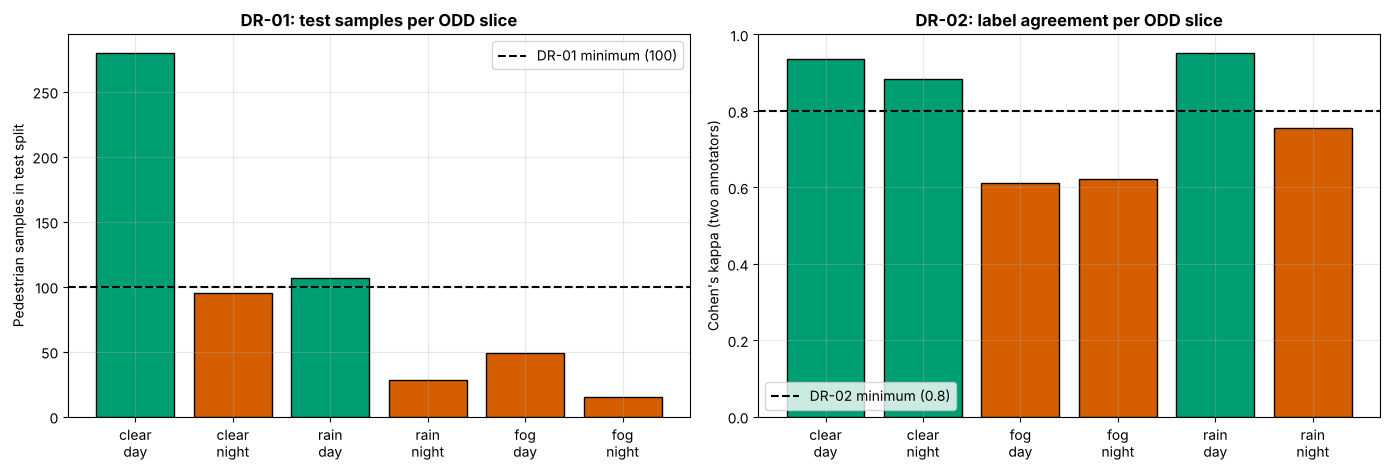

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
ax = axes[0]
x = np.arange(len(counts))
ax.bar(x, counts.values, color=[OI[2] if c >= MIN_PER_SLICE else OI[5] for c in counts.values], edgecolor="black")
ax.axhline(MIN_PER_SLICE, color="black", ls="--", label=f"DR-01 minimum ({MIN_PER_SLICE})")
ax.set_xticks(x); ax.set_xticklabels([f"{w}\n{l}" for w, l in counts.index])
ax.set_ylabel("Pedestrian samples in test split"); ax.set_title("DR-01: test samples per ODD slice", fontweight="bold")
ax.legend()
ax = axes[1]
kap = sub.groupby(["weather", "light"]).apply(lambda g: cohen_kappa_score(g.cls, g.cls2), include_groups=False)
ax.bar(range(len(kap)), kap.values, color=[OI[2] if k >= MIN_KAPPA else OI[5] for k in kap.values], edgecolor="black")
ax.axhline(MIN_KAPPA, color="black", ls="--", label=f"DR-02 minimum ({MIN_KAPPA})")
ax.set_xticks(range(len(kap))); ax.set_xticklabels([f"{w}\n{l}" for w, l in kap.index])
ax.set_ylim(0, 1); ax.set_ylabel("Cohen's kappa (two annotators)")
ax.set_title("DR-02: label agreement per ODD slice", fontweight="bold"); ax.legend(loc="lower left")
plt.tight_layout(); plt.show()

**What to take from this:**
- A single averaged "data-quality score" would hide exactly the slices that fail (rare weather at night).
- A random *frame-level* split leaks near-duplicate frames from the same recording into the test set and inflates test performance; splitting by sequence removes the leakage.
- Failed checks lead to actions in the dataset lifecycle: targeted collection for the thin slices, label-guideline revision and re-annotation for low-agreement slices.

## 6. Monitoring during operation and controlled updates

In the field, **ground-truth labels are not available online**, so an ML component cannot "measure its own accuracy" while driving. Operation-phase measures (ISO/PAS 8800 measures during operation; ISO/TS 5083 post-deployment; UL 4600 SPIs) therefore combine:

1. **Label-free runtime proxies**: input-distribution drift statistics, OOD scores, predictive entropy, cross-sensor consistency (camera vs LiDAR vs radar), temporal consistency of tracks.
2. **Periodic labelled audits**: samples of field data are uploaded, labelled offline and evaluated, which gives an accuracy estimate with a confidence interval, but only with a delay.
3. **Triggers and change management**: when a proxy or an audit crosses a threshold, collect data, analyse the cause (seasonal change, new object types, sensor degradation), retrain, run regression tests on the old test slices and new ones, and release through the update process (UN R156 / ISO 24089).

> **Illustrative data:** values below are synthetic, chosen for teaching; they are not measurements.

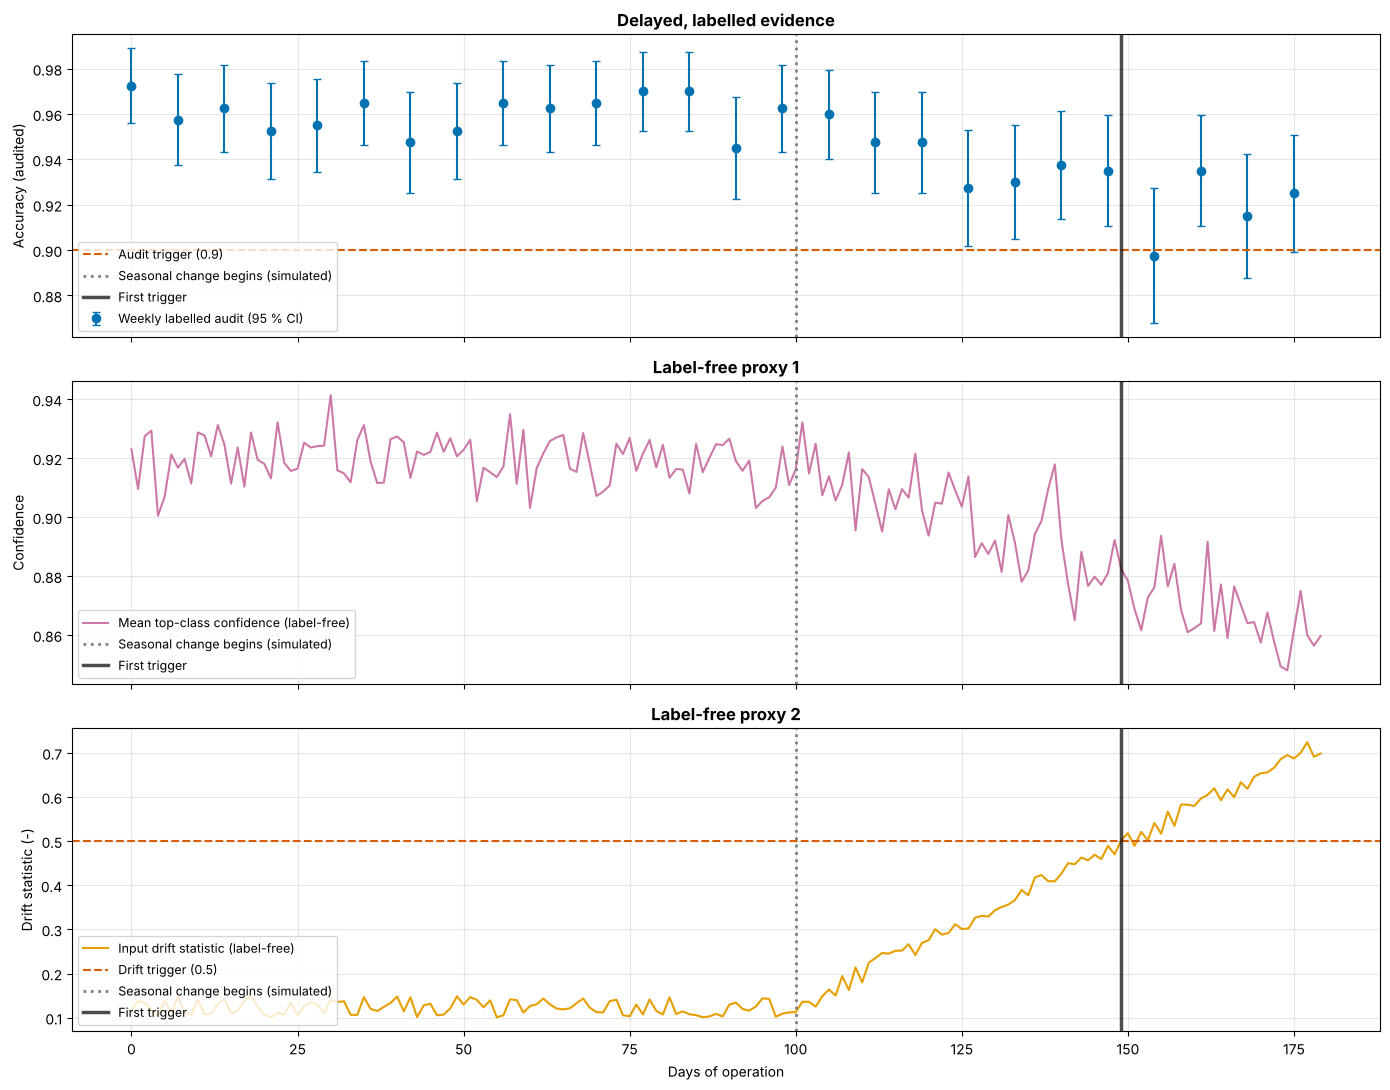

Days 0-99: mean confidence 0.919, mean drift 0.123
Days 100-179: mean confidence 0.888, mean drift 0.423
Trigger on day 149: drift metric 0.502 > 0.5
Trigger on day 154: audited accuracy 0.897 < 0.9

First trigger: day 149 (drift metric 0.502 > 0.5), 49 days after the simulated change began.


In [8]:
def simulate_model_monitoring(seed=42):
    r = np.random.default_rng(seed)
    days = np.arange(180); drift_start = 100
    ramp = np.clip((days - drift_start) / 50, 0, None)
    # Label-free proxies, available daily
    confidence = np.clip(0.92 + 0.01 * r.standard_normal(180) - 0.04 * ramp, 0.6, 0.99)
    drift = np.clip(0.10 + 0.05 * r.random(180) + 0.30 * np.clip((days - drift_start) / 40, 0, None), 0, 1.5)
    # Labelled audit: every 7 days, 400 field frames labelled offline -> accuracy with 95 % Wilson CI
    audit_days = days[::7]
    true_acc = 0.96 - 0.03 * ramp[audit_days]
    n_audit = 400
    correct = r.binomial(n_audit, np.clip(true_acc, 0, 1))
    p_hat = correct / n_audit
    z = 1.96
    centre = (p_hat + z**2 / (2 * n_audit)) / (1 + z**2 / n_audit)
    half = z * np.sqrt(p_hat * (1 - p_hat) / n_audit + z**2 / (4 * n_audit**2)) / (1 + z**2 / n_audit)

    DRIFT_LIMIT, ACC_LIMIT = 0.5, 0.90
    drift_trigger = days[drift > DRIFT_LIMIT]
    audit_trigger = audit_days[p_hat < ACC_LIMIT]
    candidates = []
    if len(drift_trigger): candidates.append((drift_trigger[0], f"drift metric {drift[drift_trigger[0]]:.3f} > {DRIFT_LIMIT}"))
    if len(audit_trigger): candidates.append((audit_trigger[0], f"audited accuracy {p_hat[audit_days == audit_trigger[0]][0]:.3f} < {ACC_LIMIT}"))

    fig, axes = plt.subplots(3, 1, figsize=(14, 11), sharex=True)
    axes[0].errorbar(audit_days, p_hat, yerr=half, fmt="o", color=OI[4], capsize=3, label="Weekly labelled audit (95 % CI)")
    axes[0].axhline(ACC_LIMIT, color=OI[5], ls="--", label=f"Audit trigger ({ACC_LIMIT})")
    axes[0].set_ylabel("Accuracy (audited)"); axes[0].set_title("Delayed, labelled evidence", fontweight="bold")
    axes[1].plot(days, confidence, color=OI[6], label="Mean top-class confidence (label-free)")
    axes[1].set_ylabel("Confidence"); axes[1].set_title("Label-free proxy 1", fontweight="bold")
    axes[2].plot(days, drift, color=OI[0], label="Input drift statistic (label-free)")
    axes[2].axhline(DRIFT_LIMIT, color=OI[5], ls="--", label=f"Drift trigger ({DRIFT_LIMIT})")
    axes[2].set_ylabel("Drift statistic (-)"); axes[2].set_xlabel("Days of operation")
    axes[2].set_title("Label-free proxy 2", fontweight="bold")
    for ax in axes:
        ax.axvline(drift_start, color="grey", ls=":", lw=2, label="Seasonal change begins (simulated)")
    if candidates:
        first_day, reason = min(candidates)
        for ax in axes:
            ax.axvline(first_day, color="black", lw=2.5, alpha=0.7, label="First trigger")
    for ax in axes:
        ax.legend(loc="lower left", fontsize=9)
    plt.tight_layout(); plt.show()

    print(f"Days 0-{drift_start - 1}: mean confidence {confidence[:drift_start].mean():.3f}, mean drift {drift[:drift_start].mean():.3f}")
    print(f"Days {drift_start}-179: mean confidence {confidence[drift_start:].mean():.3f}, mean drift {drift[drift_start:].mean():.3f}")
    for day, reason in sorted(candidates):
        print(f"Trigger on day {day}: {reason}")
    if candidates:
        first_day, reason = min(candidates)
        print(f"\nFirst trigger: day {first_day} ({reason}), "
              f"{first_day - drift_start} days after the simulated change began.")
    else:
        print("No trigger fired in the simulated period.")

simulate_model_monitoring()

Compare the trigger days printed above. Label-free proxies are available daily but are only indirect evidence of an accuracy loss; labelled audits measure accuracy directly but only weekly, with sampling error, and with a labelling delay. A sound operation concept uses both, and defines in advance what each trigger leads to.

## 7. Human–AI interaction

For SAE Level 2 and 3 systems the human is part of the safety concept:

1. **Driver monitoring**: attention and readiness to take over.
2. **Takeover requests (TOR)**: sufficient warning time, clear cues, a minimal risk manoeuvre if the driver does not respond (Level 3).
3. **Mode-confusion prevention**: unambiguous indication of the active automation mode.
4. **Trust calibration**: avoid over-trust (complacency) and under-trust (disuse) by communicating limitations honestly.

Explanations and uncertainty indicators for the driver are an HMI design question; they must be validated with users, because more information is not automatically safer.

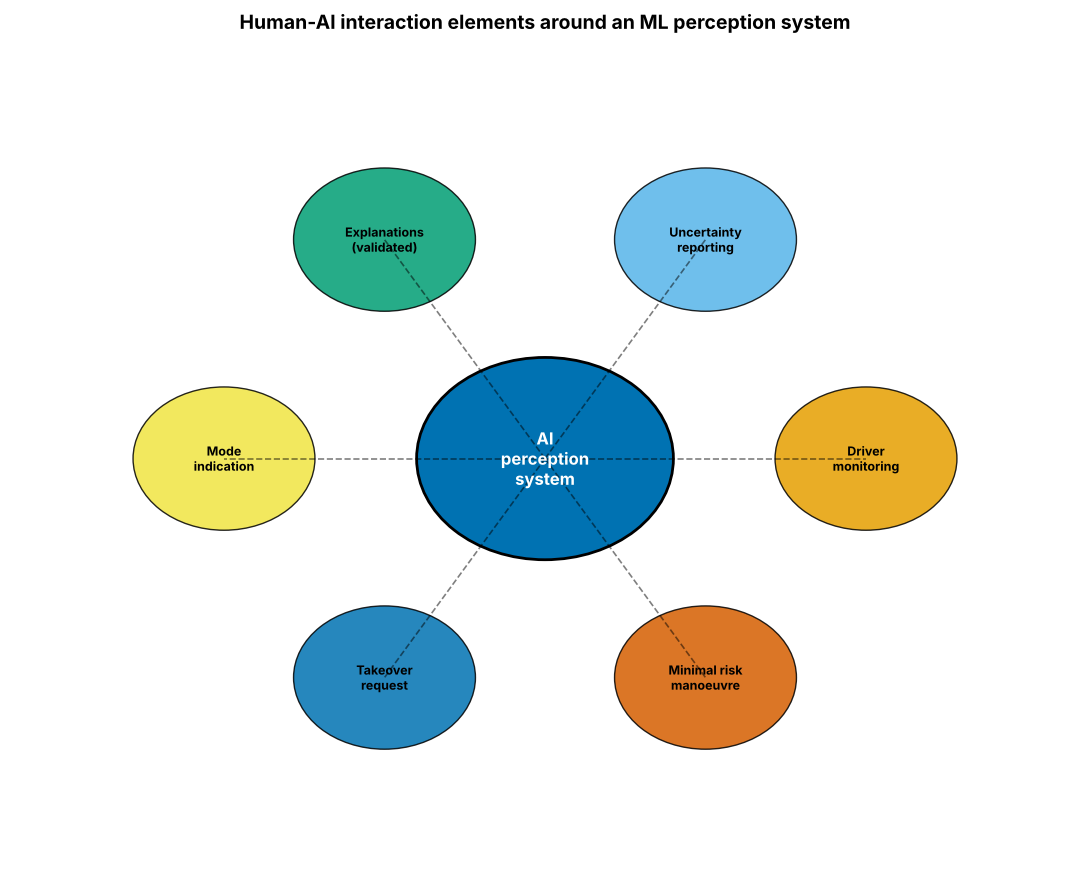

In [9]:
def visualize_human_ai_safety():
    fig, ax = plt.subplots(figsize=(11, 9))
    ax.add_patch(Circle((0.5, 0.5), 0.12, facecolor=OI[4], edgecolor="black", lw=2))
    ax.text(0.5, 0.5, "AI\nperception\nsystem", ha="center", va="center", fontsize=12, fontweight="bold", color="white")
    comps = ["Driver\nmonitoring", "Uncertainty\nreporting", "Explanations\n(validated)", "Mode\nindication",
             "Takeover\nrequest", "Minimal risk\nmanoeuvre"]
    for i, name in enumerate(comps):
        a = np.deg2rad(60 * i)
        x, y = 0.5 + 0.30 * np.cos(a), 0.5 + 0.30 * np.sin(a)
        ax.plot([0.5, x], [0.5, y], "k--", lw=1.2, alpha=0.5)
        ax.add_patch(Circle((x, y), 0.085, facecolor=OI[i], edgecolor="black", alpha=0.85))
        ax.text(x, y, name, ha="center", va="center", fontsize=9, fontweight="bold")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis("off")
    ax.set_title("Human-AI interaction elements around an ML perception system", fontsize=14, fontweight="bold")
    plt.tight_layout(); plt.show()

visualize_human_ai_safety()

## 8. Regulatory context: the EU AI Act and vehicles (as of October 2026)

- The **EU AI Act**, Regulation (EU) 2024/1689, entered into force on 1 August 2024 ([EUR-Lex](https://eur-lex.europa.eu/eli/reg/2024/1689/oj)).
- AI systems that are **safety components of vehicles** fall under products covered by the Union harmonisation legislation in **Annex I, Section B**, which includes the vehicle type-approval Regulation (EU) 2018/858 and the General Safety Regulation (EU) 2019/2144. They are high-risk via **Article 6(1)**.
- For Annex I Section B products, **Article 2(2)** limits the directly applicable provisions. In the original text these were Article 6(1), Articles 102 to 109 and Article 112; the Digital Omnibus extended the list (consolidated wording reported as "Article 6(1), Article 60a and Articles 102 to 112", [AI Act Explorer](https://artificialintelligenceact.eu/article/2/)).
- Articles 102 to 109 amend the sectoral acts (e.g. Article 107 for Regulation (EU) 2018/858) so that future **delegated and implementing acts on AI safety components take the AI Act's high-risk requirements (Chapter III, Section 2) into account**. In other words, the AI Act reaches vehicles **indirectly, through type-approval legislation**, not through a separate AI-Act conformity assessment.
- The **Digital Omnibus on AI**, Regulation (EU) 2026/1744, was published in the Official Journal on 24 July 2026 and entered into force on 27 July 2026. It postponed the high-risk obligations: reported dates are **2 December 2027** for Annex III (stand-alone) systems and **2 August 2028** for systems linked to Annex I product legislation ([EUR-Lex ELI](https://eur-lex.europa.eu/eli/reg/2026/1744/oj); dates as summarised by [ERTICO](https://ertico.com/digital-omnibus-on-ai-enters-into-force-what-it-means-for-the-mobility-sector) and the [NI Assembly EU-law tracker](https://www.niassembly.gov.uk/assembly-business/brexit-and-beyond/eu-law-scrutiny-tracker/regulation-2026-1744/); check the consolidated text for the binding wording).

The practical consequence for an automotive perception team is that ISO/PAS 8800-style engineering evidence is what type-approval authorities and future delegated acts are likely to draw on. Module 08 covers type approval in detail: [08/02 Regulation and type approval](../08_Standards_Regulation_and_Safety_Case/02_regulation_and_type_approval.ipynb).

## 9. An integrated checklist

The checklist below groups typical work products by standard. The completion status is drawn at random, purely to illustrate how such a dashboard can be presented.

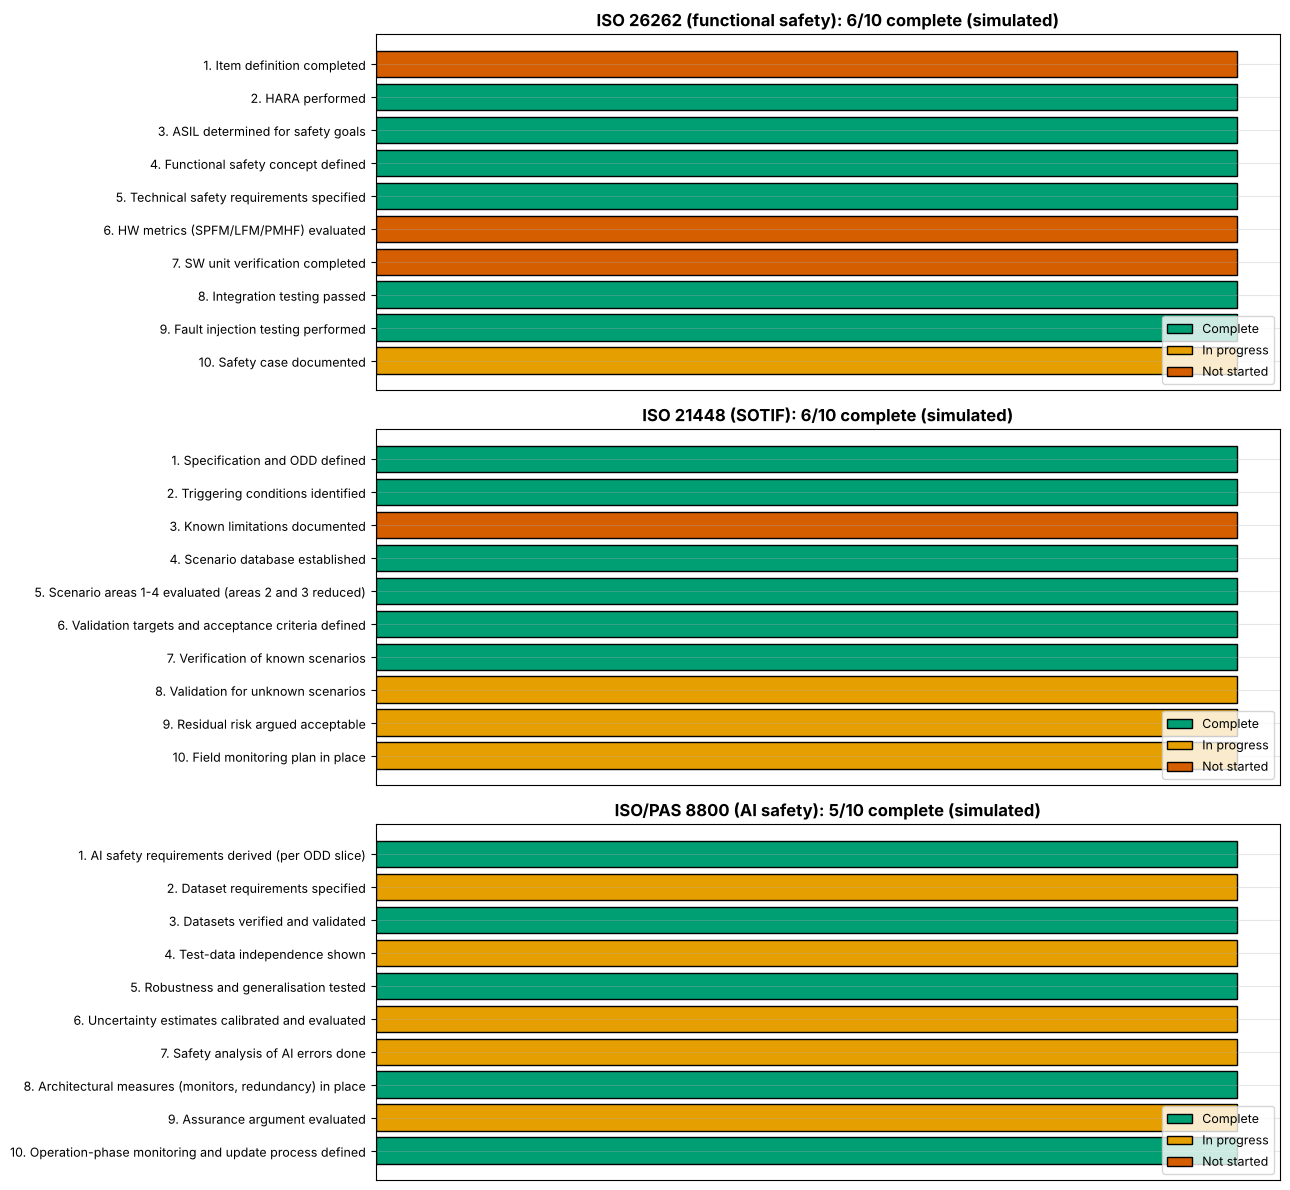

ISO 26262 (functional safety): complete 6, in progress 1, not started 3
ISO 21448 (SOTIF): complete 6, in progress 3, not started 1
ISO/PAS 8800 (AI safety): complete 5, in progress 5, not started 0
Overall (simulated): 17/30 = 57% complete. A percentage of ticked items is not a safety argument; the assurance argument must show why the evidence is sufficient.


In [10]:
checklist = {
    "ISO 26262 (functional safety)": [
        "Item definition completed", "HARA performed", "ASIL determined for safety goals",
        "Functional safety concept defined", "Technical safety requirements specified",
        "HW metrics (SPFM/LFM/PMHF) evaluated", "SW unit verification completed",
        "Integration testing passed", "Fault injection testing performed", "Safety case documented"],
    "ISO 21448 (SOTIF)": [
        "Specification and ODD defined", "Triggering conditions identified", "Known limitations documented",
        "Scenario database established", "Scenario areas 1-4 evaluated (areas 2 and 3 reduced)",
        "Validation targets and acceptance criteria defined", "Verification of known scenarios",
        "Validation for unknown scenarios", "Residual risk argued acceptable", "Field monitoring plan in place"],
    "ISO/PAS 8800 (AI safety)": [
        "AI safety requirements derived (per ODD slice)", "Dataset requirements specified",
        "Datasets verified and validated", "Test-data independence shown", "Robustness and generalisation tested",
        "Uncertainty estimates calibrated and evaluated", "Safety analysis of AI errors done",
        "Architectural measures (monitors, redundancy) in place", "Assurance argument evaluated",
        "Operation-phase monitoring and update process defined"],
}
status_colors = {"Complete": OI[2], "In progress": OI[0], "Not started": OI[5]}
completion = {s: {item: rng.choice(list(status_colors), p=p) for item in items}   # Simulated status for illustration only
              for (s, items), p in zip(checklist.items(), [[0.7, 0.2, 0.1], [0.6, 0.3, 0.1], [0.5, 0.4, 0.1]])}

fig, axes = plt.subplots(3, 1, figsize=(13, 12))
for ax, (std, items) in zip(axes, checklist.items()):
    st = [completion[std][i] for i in items]
    ax.barh(range(len(items)), 1, color=[status_colors[s] for s in st], edgecolor="black")
    ax.set_yticks(range(len(items))); ax.set_yticklabels([f"{k+1}. {t}" for k, t in enumerate(items)], fontsize=9)
    ax.set_xticks([]); ax.invert_yaxis()
    done = st.count("Complete")
    ax.set_title(f"{std}: {done}/{len(items)} complete (simulated)", fontweight="bold")
    ax.legend(handles=[Patch(facecolor=c, edgecolor="black", label=s) for s, c in status_colors.items()],
              loc="lower right", fontsize=9)
plt.tight_layout(); plt.show()

total = sum(len(v) for v in checklist.values())
complete = sum(s == "Complete" for d in completion.values() for s in d.values())
for std, d in completion.items():
    vals = list(d.values())
    print(f"{std}: complete {vals.count('Complete')}, in progress {vals.count('In progress')}, not started {vals.count('Not started')}")
print(f"Overall (simulated): {complete}/{total} = {complete / total:.0%} complete. "
      "A percentage of ticked items is not a safety argument; the assurance argument must show why the evidence is sufficient.")

## Key takeaways

- **ISO/PAS 8800:2024** is the automotive reference for AI safety. It tailors and extends ISO 26262 and ISO 21448 for AI elements rather than replacing them.
- Its core ideas are an **iterative AI safety lifecycle**, **AI safety requirements expressed through safety-related properties and the ODD**, a **dataset lifecycle** with verifiable dataset requirements, **statistical V&V**, **safety analysis of AI errors**, an **assurance argument**, and **measures during operation**.
- Keep the boundary sharp: E/E malfunctions → ISO 26262; functional insufficiencies and triggering conditions → ISO 21448; AI-specific insufficiencies → ISO/PAS 8800.
- ISO/IEC TR 5469 and TR 24028 are informative; ISO/IEC 42001 certifies organisations, not products; ISO/TS 5083 and UL 4600 address the ADS-level safety case.
- The EU AI Act reaches vehicles indirectly through type-approval legislation (Annex I Section B, Article 2(2)); the Digital Omnibus (Reg. (EU) 2026/1744) moved the Annex I-linked high-risk date to 2 August 2028 (as of October 2026).
- Data quality must be expressed as **requirements per ODD slice** and verified; averaged scores hide failures.
- Field monitoring uses label-free proxies plus periodic labelled audits, because ground truth is not available online.

## Self-assessment

1. Which kinds of causes of hazardous behaviour are addressed by ISO 26262, ISO 21448 and ISO/PAS 8800 respectively?
2. Name four topics that ISO/PAS 8800 covers beyond what ISO 26262 provides.
3. Why is ISO/IEC 42001 certification not evidence that a perception component is safe?
4. Why does a frame-level random split overstate test performance on driving data?
5. How does the EU AI Act apply to an ML-based safety component of a type-approved passenger car?
6. Why can a vehicle not monitor its detector's accuracy online, and what is done instead?

<details>
<summary>Answers</summary>

1. ISO 26262: malfunctions due to systematic or random hardware faults of E/E systems. ISO 21448: hazardous behaviour caused by functional insufficiencies (of the specification or performance) together with triggering conditions, without a fault. ISO/PAS 8800: AI-specific insufficiencies and errors (data, model, training), by tailoring both.
2. For example: derivation of AI safety requirements via safety-related properties; data-related considerations and a dataset lifecycle; V&V of the AI system (per ODD slice, robustness, generalisation); safety analysis of AI errors; assurance argument for AI systems; measures during operation; confidence in AI frameworks and tools.
3. 42001 is a management-system standard. It shows that an organisation has processes for governing AI, not that a particular product meets its safety requirements.
4. Consecutive frames of one recording are nearly identical, so frames in the test set have near-duplicates in the training set. The test then measures memorisation rather than generalisation. Splitting by recording sequence (or location/time) avoids this.
5. Such a component is high-risk via Article 6(1) because vehicle type-approval legislation is listed in Annex I Section B. Article 2(2) restricts the directly applicable provisions; the AI Act requirements are brought in through delegated and implementing acts under the type-approval regulations (e.g. Article 107 amending Regulation (EU) 2018/858). The Digital Omnibus postponed the Annex I-linked high-risk date to 2 August 2028 (as of October 2026).
6. Ground-truth labels do not exist at runtime. Monitoring relies on label-free proxies (drift, OOD scores, entropy, cross-sensor and temporal consistency) and on periodic offline audits of uploaded field data, with defined triggers for analysis, retraining and regression testing.
</details>

## References

- ISO/PAS 8800:2024 *Road vehicles — Safety and artificial intelligence*. https://www.iso.org/standard/83303.html
- ISO 26262:2018 *Road vehicles — Functional safety* (Parts 1–12).
- ISO 21448:2022 *Road vehicles — Safety of the intended functionality*.
- ISO/IEC TR 5469:2024 *Artificial intelligence — Functional safety and AI systems*.
- ISO/IEC 22989:2022 *Artificial intelligence concepts and terminology*.
- ISO/IEC TR 24028:2020 *Overview of trustworthiness in artificial intelligence*.
- ISO/IEC 23894:2023 *AI — Guidance on risk management*; ISO/IEC 42001:2023 *AI — Management system*.
- ISO/IEC 5259-1:2024 to 5259-5:2025 *Data quality for analytics and machine learning*. https://www.iso.org/standard/81088.html
- ISO/TS 5083:2025 *Road vehicles — Safety for automated driving systems — Design, verification and validation*. https://www.iso.org/standard/81920.html
- UL 4600 *Standard for Evaluation of Autonomous Products*, 3rd ed. (2023).
- NIST AI Risk Management Framework 1.0 (2023). https://doi.org/10.6028/NIST.AI.100-1
- Regulation (EU) 2024/1689 (AI Act). https://eur-lex.europa.eu/eli/reg/2024/1689/oj ; Regulation (EU) 2026/1744 (Digital Omnibus on AI). https://eur-lex.europa.eu/eli/reg/2026/1744/oj
- Patel, M., Jung, R., Khatun, M. (2025). A Systematic Literature Review on Safety of the Intended Functionality for Automated Driving Systems. SAE Technical Paper 2025-01-5030. https://doi.org/10.4271/2025-01-5030
- Patel, M., Jung, R. (2026). Integrating Cybersecurity Into the AI Safety Assurance Argument: A GSN Pattern for AI-Based Perception Components in Highly Automated Driving. In *Computer Safety, Reliability, and Security. SAFECOMP 2026 Workshops*, LNCS, pp. 763–779. Springer. https://doi.org/10.1007/978-3-032-35506-5_55
- Hawkins, R. et al. (2021). Guidance on the Assurance of Machine Learning in Autonomous Systems (AMLAS). arXiv:2102.01564.

---
**Navigation:** ← [README](README.md) · [Module index](README.md) · [02 Uncertainty types](02_uncertainty_types.ipynb) →

### Further practice

- The author's companion repository [AI-Perception-Safety-Workshop](https://github.com/milinpatel07/AI-Perception-Safety-Workshop) contains further hands-on exercises on MC dropout and explainability.
- Module 08 builds a GSN safety case: [08/04 Safety case (GSN)](../08_Standards_Regulation_and_Safety_Case/04_safety_case_gsn.ipynb).